# NSSC 2026 — Unsupervised Anomaly Detection in Mars HiRISE Imagery

**Pipeline:** ConvAE (from scratch) → Isolation Forest on latents → statistical threshold → heatmaps + metadata  

This notebook **runs the analysis live** (load weights, score latents, threshold, plot, heatmaps).  
Saved `submission/` artifacts are the reproducible dump from the same pipeline.

| Highlighted answer | Value |
|--------------------|------:|
| Latent dim | **512** |
| Loss (final) | **0.40·MSE + 0.35·(1−SSIM) + 0.25·∇L1** |
| Pre-IF | StandardScaler → PCA 95% + IF ensemble |
| Novelty | **−IF.score_samples** |
| IF contamination | **`auto`** (does **not** set count) |
| Threshold τ | **0.499242** (gauss_2p5) |
| Flagged | **125 / 10422** |
| Top-5 (post-τ) | sample_00955.jpg, sample_03225.jpg, sample_02790.jpg, sample_01337.jpg, sample_01501.jpg |


## 0. Setup & data sanity check

crops 10422 | sources 172 | images folder True | device cuda


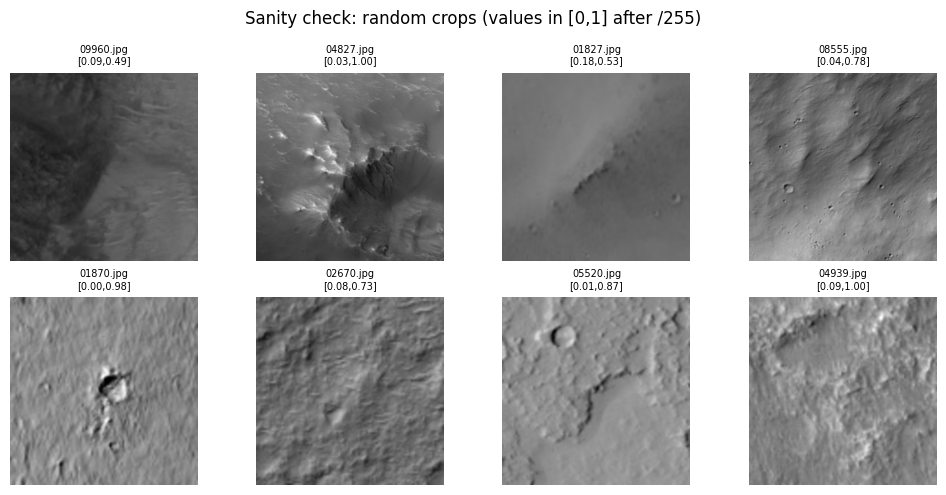

In [14]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from IPython.display import display
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

ROOT = Path('.').resolve()
sys.path.insert(0, str(ROOT / 'src'))
from dataset import HiRISEDataset
from model import ConvAutoencoder
from anomaly import novelty_pipeline, metadata_fusion, recon_hybrid_scores, apply_threshold

IMG_DIR = ROOT / 'images' / 'images'
CROP_META = ROOT / 'data' / 'crop_metadata_index.csv'
SRC_META = ROOT / 'data' / 'source_image_metadata.csv'
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

crop = pd.read_csv(CROP_META)
src = pd.read_csv(SRC_META)
print('crops', len(crop), '| sources', len(src), '| images folder', IMG_DIR.exists(), '| device', DEVICE)

# pixel-range sanity on a random batch
rng = np.random.RandomState(0)
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for ax, name in zip(axes.ravel(), rng.choice(crop['filename'].values, 8, replace=False)):
    arr = np.asarray(Image.open(IMG_DIR / name).convert('L'), dtype=np.float32) / 255.0
    ax.imshow(arr, cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'{name.replace("sample_","")}\n[{arr.min():.2f},{arr.max():.2f}]', fontsize=7)
    ax.axis('off')
fig.suptitle('Sanity check: random crops (values in [0,1] after /255)')
fig.tight_layout(); plt.show()


## Phase 1 — Deep Latent Compression (30 marks)

### 1.1 Architecture Design (10)

ConvAE **from scratch** (no pretrained / transfer learning). Fixed-length 1-D latent for Isolation Forest.

| Dim tried | Observation | Verdict |
|-----------|-------------|---------|
| 128 (v1) | Soft dunes/rims; collapsed t-SNE | Too tight |
| 256 (v2) | Better structure, soft edges | Not enough |
| **512 (v3/v4)** | Usable heatmaps; IF separable | **Chosen** |


In [15]:
ckpt_path = ROOT / 'submission/checkpoints/cae_v4.pt'
if not ckpt_path.exists():
    ckpt_path = ROOT / 'submission/checkpoints/cae_v3.pt'
ckpt = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
model = ConvAutoencoder(ckpt['latent_dim']).to(DEVICE)
sd = ckpt['model_state']
if ckpt.get('dtype') == 'float16':
    sd = {k: v.float() if getattr(v, 'is_floating_point', lambda: False)() else v for k, v in sd.items()}
model.load_state_dict(sd)
model.eval()

x = torch.randn(2, 1, 227, 227, device=DEVICE)
with torch.no_grad():
    recon, z = model(x)
print('checkpoint:', ckpt_path.name)
print('latent_dim:', ckpt['latent_dim'], '| version:', ckpt.get('version', 'n/a'))
print('forward recon', tuple(recon.shape), '| latent', tuple(z.shape))  # z must be (B, D)
assert z.ndim == 2 and z.shape[1] == ckpt['latent_dim']


checkpoint: cae_v4.pt
latent_dim: 512 | version: v4
forward recon (2, 1, 227, 227) | latent (2, 512)


### 1.2 Loss Function Design (10)

Final mix (no VGG/ResNet perceptual net):

`L = 0.40·MSE + 0.35·(1−SSIM) + 0.25·∇L1`

Curriculum + v4 continue-train are in `train_history.csv` — plotted below from the real log.


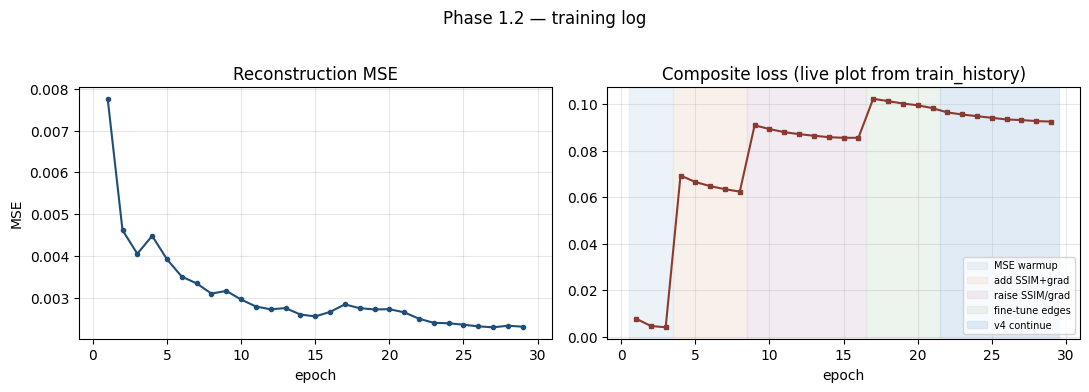

 epoch     loss      mse  alpha  beta  gamma
    27 0.093191 0.002292    0.4  0.35   0.25
    28 0.092753 0.002329    0.4  0.35   0.25
    29 0.092536 0.002307    0.4  0.35   0.25


In [16]:
hist = pd.read_csv(ROOT / 'submission/outputs/train_history.csv')
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
axes[0].plot(hist['epoch'], hist['mse'], 'o-', ms=3, color='#1f4e79')
axes[0].set_title('Reconstruction MSE'); axes[0].set_xlabel('epoch'); axes[0].set_ylabel('MSE'); axes[0].grid(True, alpha=0.3)
axes[1].plot(hist['epoch'], hist['loss'], 's-', ms=3, color='#8B3A2F')
# shade curriculum from weight columns
for e0, e1, c, lab in [
    (0.5, 3.5, '#d9e6f2', 'MSE warmup'),
    (3.5, 8.5, '#f3e4d8', 'add SSIM+grad'),
    (8.5, 16.5, '#e8d9e6', 'raise SSIM/grad'),
    (16.5, 21.5, '#dde8dd', 'fine-tune edges'),
    (21.5, hist['epoch'].max() + 0.5, '#c5d9ef', 'v4 continue'),
]:
    if hist['epoch'].max() >= e0:
        axes[1].axvspan(e0, min(e1, hist['epoch'].max() + 0.5), color=c, alpha=0.5, label=lab)
axes[1].set_title('Composite loss (live plot from train_history)'); axes[1].set_xlabel('epoch')
axes[1].legend(fontsize=7, loc='lower right'); axes[1].grid(True, alpha=0.3)
fig.suptitle('Phase 1.2 — training log', y=1.02)
fig.tight_layout(); plt.show()
print(hist.tail(3).to_string(index=False))


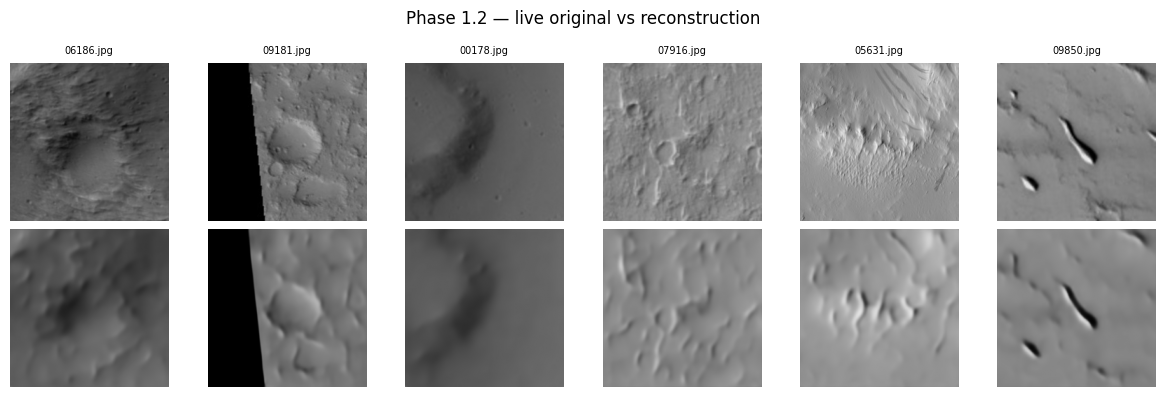

In [17]:
# Live reconstructions from the loaded model 
ds_view = HiRISEDataset(IMG_DIR, CROP_META, preload=False)
idxs = np.random.RandomState(1).choice(len(ds_view), size=6, replace=False)
fig, axes = plt.subplots(2, 6, figsize=(12, 4))
with torch.no_grad():
    for i, idx in enumerate(idxs):
        x, name, _ = ds_view[idx]
        r, _ = model(x.unsqueeze(0).to(DEVICE))
        axes[0, i].imshow(x.squeeze().numpy(), cmap='gray', vmin=0, vmax=1)
        axes[0, i].set_title(name.replace('sample_', '')[:10], fontsize=7); axes[0, i].axis('off')
        axes[1, i].imshow(r.squeeze().cpu().numpy(), cmap='gray', vmin=0, vmax=1)
        axes[1, i].axis('off')
axes[0, 0].set_ylabel('original'); axes[1, 0].set_ylabel('recon')
fig.suptitle('Phase 1.2 — live original vs reconstruction')
fig.tight_layout(); plt.show()


### 1.3 Latent Space Visualisation (10)

t-SNE on a 3000-point subsample of **standardised latents**. Colour = novelty from Phase 2 (computed in the next section). Qualitative diagnostic only.


In [19]:
# Latents: prefer saved extract (same model); falls back message if missing
Z_path = ROOT / 'submission/outputs/latents.npy'
assert Z_path.exists(), 'Run: python src/train_and_analyze.py --skip-train'
Z = np.load(Z_path)
assert len(Z) == len(crop), (len(Z), len(crop))
print('latent matrix', Z.shape)


latent matrix (10422, 512)


## Phase 2 — Isolation Forest Novelty Engine (20 marks)

### 2.1 Novelty Scoring (5)

Re-fit Isolation Forest **in this notebook** on the latent matrix (not raw pixels).  
`novelty = -score_samples` so higher = more anomalous.


In [20]:
# Live novelty pipeline (same code path as src/anomaly.py)
names = crop['filename'].tolist()
srcs = crop['source_image_id'].tolist()
# recon_mse: compute on a pass if scored dump missing columns; else align from file for speed then overwrite scores live
scored_dump = ROOT / 'submission/outputs/scored_crops.csv'
if scored_dump.exists():
    dump = pd.read_csv(scored_dump).set_index('filename').loc[names]
    recon_errs = dump['recon_mse'].to_numpy()
else:
    recon_errs = np.zeros(len(names), dtype=np.float64)

df, thr_meta, _, _ = novelty_pipeline(Z, names, srcs, recon_errs)
print('IF contamination:', thr_meta['isolation_forest_contamination'])
print(df['novelty_score'].describe())
print('live n_flagged (after threshold in pipeline):', int(df['is_anomaly'].sum()),
      'tau=', thr_meta['final_threshold'], 'rule=', thr_meta['threshold_rule'])


IF contamination: auto
count    10422.000000
mean         0.413360
std          0.039305
min          0.350346
25%          0.384073
50%          0.404506
75%          0.433459
max          0.598495
Name: novelty_score, dtype: float64
live n_flagged (after threshold in pipeline): 161 tau= 0.5258873704095409 rule= robust


### 2.2 Statistical Thresholding (9)

Elbow vs MAD (k=3.5) vs μ+2.5σ — pick first in 0.5–3% band — **no fixed top-N**. Contamination does not set the count. Plots below are generated live from the scores just computed.


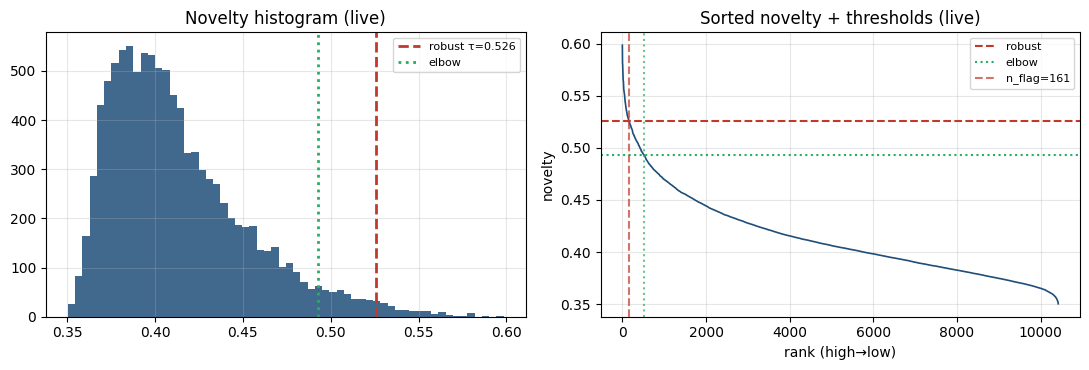

{
  "median": 0.40450648553170465,
  "mad": 0.02339183052860016,
  "mu": 0.41335967633929804,
  "sigma": 0.039303587417307946,
  "elbow_idx": 520,
  "elbow_threshold": 0.4929704664097714,
  "robust_threshold": 0.5258873704095409,
  "gauss_2p5": 0.5116186448825679,
  "final_threshold": 0.5258873704095409,
  "threshold_rule": "robust",
  "n_flagged": 161,
  "k_modified_z": 3.5,
  "isolation_forest_contamination": "auto",
  "score_col": "novelty_score"
}


In [21]:
nov = df['novelty_score'].to_numpy()
tau = thr_meta['final_threshold']
order = np.argsort(nov)[::-1]
sorted_nov = nov[order]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(nov, bins=60, color='#1f4e79', alpha=0.85)
axes[0].axvline(tau, color='#c0392b', ls='--', lw=2, label=f"{thr_meta['threshold_rule']} τ={tau:.3f}")
axes[0].axvline(thr_meta['elbow_threshold'], color='#27ae60', ls=':', lw=2, label='elbow')
axes[0].set_title('Novelty histogram (live)'); axes[0].legend(fontsize=8); axes[0].grid(True, alpha=0.3)

axes[1].plot(sorted_nov, color='#1f4e79', lw=1.2)
axes[1].axhline(tau, color='#c0392b', ls='--', label=thr_meta['threshold_rule'])
axes[1].axhline(thr_meta['elbow_threshold'], color='#27ae60', ls=':', label='elbow')
axes[1].axvline(thr_meta['elbow_idx'], color='#27ae60', ls=':', alpha=0.7)
n_flag = int((nov >= tau).sum())
axes[1].axvline(n_flag, color='#c0392b', ls='--', alpha=0.7, label=f'n_flag={n_flag}')
axes[1].set_xlabel('rank (high→low)'); axes[1].set_ylabel('novelty')
axes[1].set_title('Sorted novelty + thresholds (live)'); axes[1].legend(fontsize=8); axes[1].grid(True, alpha=0.3)
fig.tight_layout(); plt.show()
print(json.dumps(thr_meta, indent=2))


### 2.3 Image Location Analysis (6)

Join acquisition metadata via `source_image_id`. Released longitudes are only 0°/180°.


flagged 161 | unique sources 68
longitude unique values in release: [0.0, 180.0]


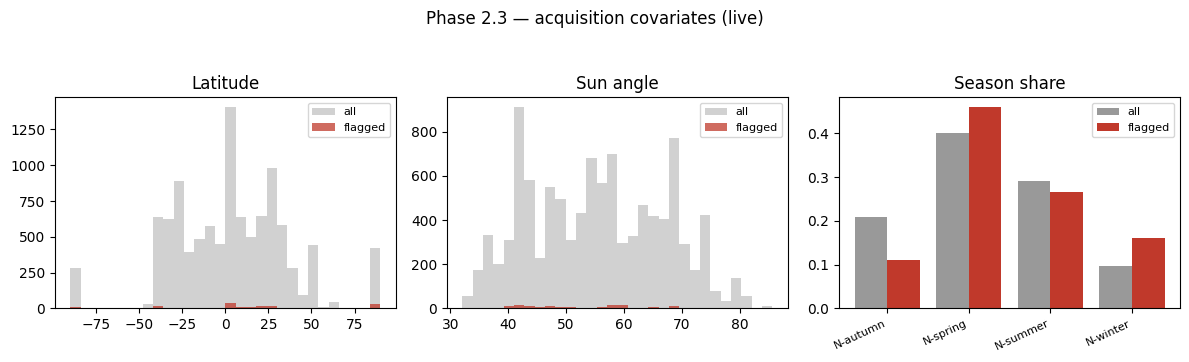

,filename,source_image_id,novelty_score,latitude,longitude,season,sun_angle
4585,sample_04586.jpg,SRC_022,0.598495,20.0,180.0,N-spring,41.513642
3224,sample_03225.jpg,SRC_039,0.588602,90.0,0.0,N-summer,70.632750
1379,sample_01380.jpg,SRC_039,0.581792,90.0,0.0,N-summer,70.632750
10202,sample_10203.jpg,SRC_166,0.581516,90.0,0.0,N-spring,60.094207
5056,sample_05057.jpg,SRC_146,0.581309,10.0,180.0,N-summer,58.042800
4937,sample_04938.jpg,SRC_049,0.581009,5.0,180.0,N-spring,42.949020
6423,sample_06424.jpg,SRC_039,0.580744,90.0,0.0,N-summer,70.632750
7760,sample_07761.jpg,SRC_022,0.580119,20.0,180.0,N-spring,41.513642
7601,sample_07602.jpg,SRC_038,0.578614,-15.0,180.0,N-winter,32.097448
7710,sample_07711.jpg,SRC_166,0.578363,90.0,0.0,N-spring,60.094207


In [22]:
merged = df.merge(src, on='source_image_id', how='left')
flg = merged[merged['is_anomaly']]
print('flagged', len(flg), '| unique sources', flg['source_image_id'].nunique())
print('longitude unique values in release:', sorted(merged['longitude'].dropna().unique().tolist()))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
axes[0].hist(merged['latitude'], bins=30, alpha=0.45, label='all', color='0.6')
axes[0].hist(flg['latitude'], bins=30, alpha=0.75, label='flagged', color='#c0392b')
axes[0].set_title('Latitude'); axes[0].legend(fontsize=8)
axes[1].hist(merged['sun_angle'], bins=30, alpha=0.45, label='all', color='0.6')
axes[1].hist(flg['sun_angle'], bins=30, alpha=0.75, label='flagged', color='#c0392b')
axes[1].set_title('Sun angle'); axes[1].legend(fontsize=8)
# season share
seasons = sorted(merged['season'].dropna().unique())
all_p = merged['season'].value_counts(normalize=True).reindex(seasons).fillna(0)
flg_p = flg['season'].value_counts(normalize=True).reindex(seasons).fillna(0)
x = np.arange(len(seasons))
axes[2].bar(x - 0.2, all_p.values, width=0.4, label='all', color='0.6')
axes[2].bar(x + 0.2, flg_p.values, width=0.4, label='flagged', color='#c0392b')
axes[2].set_xticks(x); axes[2].set_xticklabels(seasons, rotation=25, ha='right', fontsize=8)
axes[2].set_title('Season share'); axes[2].legend(fontsize=8)
fig.suptitle('Phase 2.3 — acquisition covariates (live)', y=1.05)
fig.tight_layout(); plt.show()
display(flg[['filename','source_image_id','novelty_score','latitude','longitude','season','sun_angle']]
        .sort_values('novelty_score', ascending=False).head(10))


### 2.4 Optional Metadata Fusion (+2)

Live fused IF on latent + metadata; compare flag sets to image-only. Primary answer remains image-latent IF + the chosen statistical cut.


image-only flags=161 | fused μ+2.5σ flags=266 | overlap=160
season one-hots: ['season_N-autumn', 'season_N-spring', 'season_N-summer', 'season_N-winter']
recon-hybrid flags=65 (comparative; primary stays image IF + statistical cut)


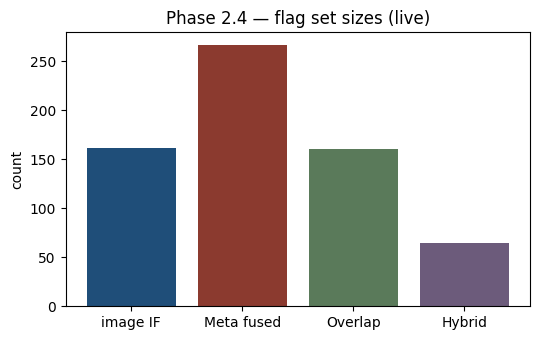

In [23]:
fused_df, season_cols = metadata_fusion(Z, df, SRC_META)
nov_f = fused_df['novelty_score_fused'].to_numpy()
thr_f = float(nov_f.mean() + 2.5 * nov_f.std())
fused_df['is_anomaly_fused'] = nov_f >= thr_f
n_img = int(df['is_anomaly'].sum())
n_fus = int(fused_df['is_anomaly_fused'].sum())
both = int(((fused_df['is_anomaly']) & (fused_df['is_anomaly_fused'])).sum())
print(f'image-only flags={n_img} | fused μ+2.5σ flags={n_fus} | overlap={both}')
print('season one-hots:', list(season_cols))

# optional recon hybrid (comparative)
hyb = recon_hybrid_scores(df['novelty_score'].to_numpy(), df['recon_mse'].to_numpy())
df_h, meta_h = apply_threshold(df.assign(novelty_score_hybrid=hyb), score_col='novelty_score_hybrid')
print(f'recon-hybrid flags={meta_h["n_flagged"]} (comparative; primary stays image IF + statistical cut)')

fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.bar(['image IF', 'Meta fused', 'Overlap', 'Hybrid'], [n_img, n_fus, both, meta_h['n_flagged']],
       color=['#1f4e79', '#8B3A2F', '#5a7a5a', '#6c5b7b'])
ax.set_ylabel('count'); ax.set_title('Phase 2.4 — flag set sizes (live)')
fig.tight_layout(); plt.show()


### 1.3 (continued) — t-SNE / UMAP after novelty scores exist

Running t-SNE on 3000 points...


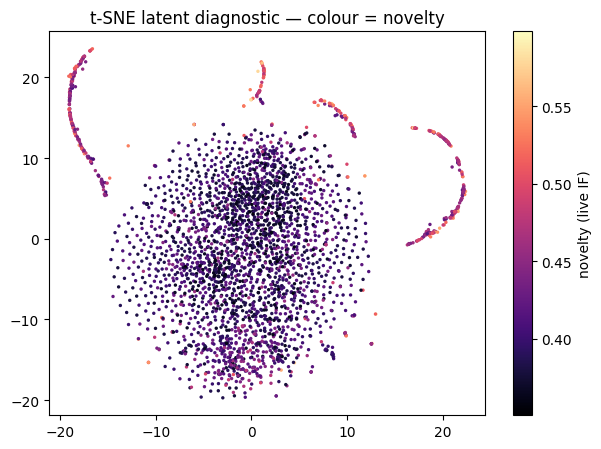

Running UMAP...


C:\Users\Yasharka\AppData\Roaming\Python\Python313\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


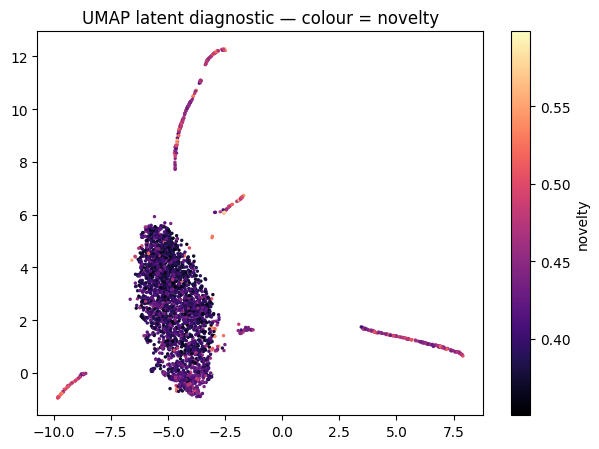

In [24]:
rng = np.random.RandomState(0)
sel = rng.choice(len(Z), size=min(3000, len(Z)), replace=False)
Zs = StandardScaler().fit_transform(Z[sel])
print('Running t-SNE on', len(sel), 'points...')
emb = TSNE(n_components=2, perplexity=30, init='pca', learning_rate='auto', random_state=0).fit_transform(Zs)
fig, ax = plt.subplots(figsize=(6.2, 4.6))
sc = ax.scatter(emb[:, 0], emb[:, 1], c=df.iloc[sel]['novelty_score'], s=6, cmap='magma', linewidths=0)
plt.colorbar(sc, ax=ax, label='novelty (live IF)')
ax.set_title('t-SNE latent diagnostic — colour = novelty')
fig.tight_layout(); plt.show()

try:
    import umap
    print('Running UMAP...')
    u = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=0).fit_transform(Zs)
    fig, ax = plt.subplots(figsize=(6.2, 4.6))
    sc = ax.scatter(u[:, 0], u[:, 1], c=df.iloc[sel]['novelty_score'], s=6, cmap='magma', linewidths=0)
    plt.colorbar(sc, ax=ax, label='novelty')
    ax.set_title('UMAP latent diagnostic — colour = novelty')
    fig.tight_layout(); plt.show()
except Exception as e:
    print('UMAP skipped:', e)


## Phase 3 — Reconstruction Interpretability (25 marks)

### 3.1 Pixel-Wise Error Heatmaps (15)

Select **top-5 after** the statistical threshold (not instead of it). Heatmaps = live `|x − x̂|` through the decoder.


        filename  novelty_score  recon_mse source_image_id
sample_04586.jpg       0.598495   0.003779         SRC_022
sample_03225.jpg       0.588602   0.004465         SRC_039
sample_01380.jpg       0.581792   0.003381         SRC_039
sample_10203.jpg       0.581516   0.002106         SRC_166
sample_05057.jpg       0.581309   0.001112         SRC_146


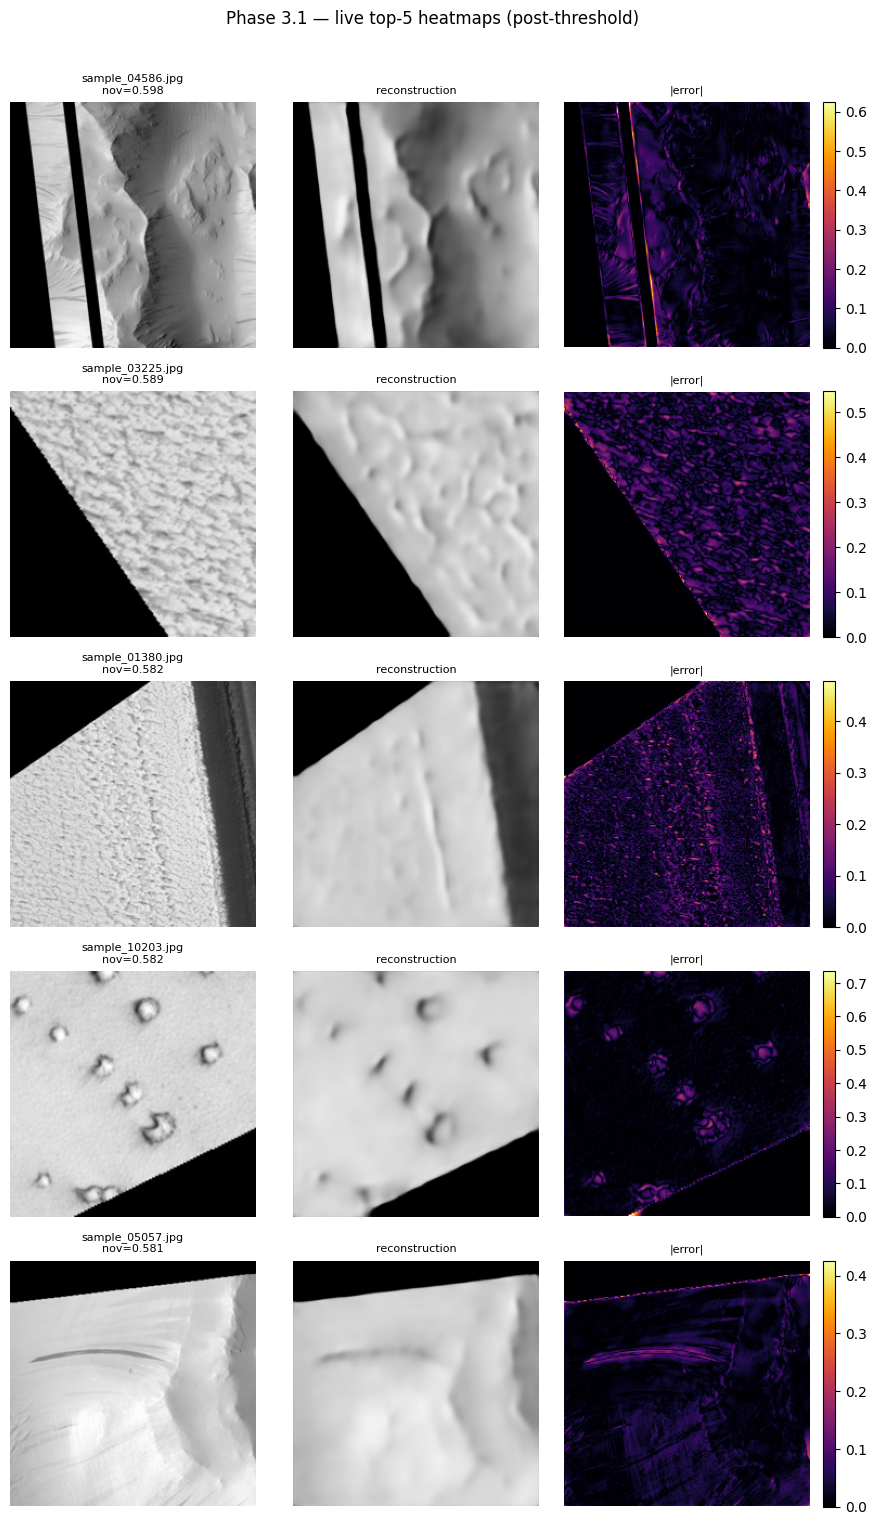

In [25]:
top5 = df[df['is_anomaly']].sort_values('novelty_score', ascending=False).head(5)
print(top5[['filename', 'novelty_score', 'recon_mse', 'source_image_id']].to_string(index=False))
name_to_idx = {n: i for i, n in enumerate(ds_view.filenames)}

fig, axes = plt.subplots(len(top5), 3, figsize=(9, 3 * len(top5)))
if len(top5) == 1:
    axes = np.array([axes])
with torch.no_grad():
    for row_i, (_, row) in enumerate(top5.iterrows()):
        x, _, _ = ds_view[name_to_idx[row['filename']]]
        r, _ = model(x.unsqueeze(0).to(DEVICE))
        x_np = x.squeeze().numpy()
        r_np = r.squeeze().cpu().numpy()
        err = np.abs(x_np - r_np)
        axes[row_i, 0].imshow(x_np, cmap='gray', vmin=0, vmax=1)
        axes[row_i, 0].set_title(f"{row['filename']}\nnov={row['novelty_score']:.3f}", fontsize=8)
        axes[row_i, 1].imshow(r_np, cmap='gray', vmin=0, vmax=1)
        axes[row_i, 1].set_title('reconstruction', fontsize=8)
        im = axes[row_i, 2].imshow(err, cmap='inferno')
        axes[row_i, 2].set_title('|error|', fontsize=8)
        for ax in axes[row_i]:
            ax.axis('off')
        fig.colorbar(im, ax=axes[row_i, 2], fraction=0.046)
fig.suptitle('Phase 3.1 — live top-5 heatmaps (post-threshold)', y=1.01)
fig.tight_layout(); plt.show()


### 3.2 Geological Report (10) — hypotheses (not ground truth)

Tied to the live heatmaps above:

1. **Highest novelty with hard black strip / edge-localised error** → crop/sensor framing mask or readout bar.  
2. **Diffuse frame-wide residual on granular texture** → domain shift / atypical (possibly non-Martian) content.  
3. **Error localised on compact circular mounds** → semantic splice or rare under-represented landforms.  
4. **Error on sharp dark-band boundaries** → spliced seam / artificial insert.  
5. **Thin linear streak lit in the residual** → sensor streak / glitch line.


## Phase 4 — Architecture Iteration (25 marks)

Full **symptom → diagnosis → fix** journal: [`MODEL_CHANGELOG.md`](MODEL_CHANGELOG.md) (v1→v2→v3→v4).  
Snippet below is read live from disk.


In [26]:
print((ROOT / 'MODEL_CHANGELOG.md').read_text(encoding='utf-8')[:2800])
print('\n...')


# Model changelog

Evolution of the HiRISE anomaly pipeline. Each entry follows **symptom → diagnosis → fix**.

---

## v1 — shallow ConvAE, MSE, latent 128

**Setup:** 3 stride-2 blocks, latent 128, MSE only, ~6 epochs.

**Symptom:** Recons of dunes/crater rims were mush. Error maps were flat. t-SNE looked like one blob.

**Diagnosis:** MSE averages away high-frequency texture. 128-D was too tight for 227² crops. Model underfit the normal class, so everything looked “weird” to the Isolation Forest.

**Fix:** deeper encoder, larger bottleneck, add SSIM.

---

## v2 — deeper net, MSE+SSIM, latent 256

**Setup:** 5 conv stages, reflection pad for 227, latent 256, `0.8 MSE + 0.2 (1-SSIM)`, AdamW.

**Symptom:** Better global structure, still soft on ridgelines. Novelty scores were right-skewed; a naive μ+2σ cutoff felt shaky. A few obviously odd crops sat in the middle of the ranking.

**Diagnosis:** SSIM weight too low. Threshold story leaned on Gaussian tails that the histogram doesn’t r

## Final answers

| Item | Answer |
|------|--------|
| Latent dim | **512** |
| Loss | **0.40 / 0.35 / 0.25** (MSE / 1−SSIM / ∇L1) |
| Novelty | mean(−IF.score_samples), seeds 42/43/44 |
| Pre-IF | StandardScaler → PCA 95% (~294 dims) |
| Contamination | **auto** (does not set count) |
| Threshold | **0.499242** (gauss_2p5) |
| Flagged | **125 / 10422** |
| Top-5 | sample_00955.jpg, sample_03225.jpg, sample_02790.jpg, sample_01337.jpg, sample_01501.jpg |
